# analyzeData

In [27]:
import json
import os
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [122]:
def scanFile(data):
    types = ["positive", "negative", "both"]
    tiers = ["<= 25%", "<= 50%", "<= 75%", "<= 100%"]
    typeIndex = 0
    
    spotNames =[]
    rawData = []
    normalizedData = []
    positives = []
    negatives = []
    
    for sample in data["samples"]:
        if not hasLowVariance(sample["data"]):
            if sample["type"][0] == "positive":
                positives.append(sample)
            else:
                negatives.append(sample)
    
    #searchForEpitopesTree(positives, searchForEpitopesArea(positives))
    posFlank = [36,40]
    positives = selectionSort(positives, posFlank)
    positives = splitSetsIntoTiers(4,(2 ** 16 -1),positives)
    negatives = splitSetsIntoTiers(4,(2 ** 16 -1),negatives)
    
    positiveEpitopes = []
    negativeEpitopes = []
    
#     for pos in positives:
#         if pos:
#             positiveEpitopes.append(searchForEpitopesArea(pos))
        
#     for neg in negatives:
#         if neg:
#             negativeEpitopes.append(searchForEpitopesArea(neg))
    
    
    
    for counter, posSet in enumerate(positives):
        xAxis, yAxis = getHeatmapAxes(posSet)
        inputData = []
        for pos in posSet:
            iData = []
            for spot in pos["data"]:
                iData.append(float(spot["normalizedIntensity"]))
                #iData.append(float(spot["rawIntensity"]))
            inputData.append(iData.copy())    
        printHeatmap("sortTest SYNI pos - "+str(counter), inputData, xAxis, yAxis)
        
#     print("Positive Epitopes: ")
#     for counter, pEpi in enumerate(positiveEpitopes):
#         print(tiers[counter])
#         for epi in pEpi:
#             print(epi)
            
#     print("Negative Epitopes: ")
#     for counter, nEpi in enumerate(negativeEpitopes):
#         print(tiers[counter])
#         for epi in nEpi:
#             print(epi)        
        
    
    
        
#     rawDat = []
#     iNormDat = []
#     setNames = []
    
#     for sample in data["samples"]:
#         if sample["type"][0] == types[typeIndex]:
#             setNames.append(sample["name"])
#             rawDat.clear()
#             iNormDat.clear()
#             for spots in sample["data"]:
#                 rawDat.append(float(spots["rawIntensity"]))
#                 iNormDat.append(float(spots["normalizedIntensity"]))
#             rawData.append(rawDat.copy())
#             normalizedData.append(iNormDat.copy())

#     normalizedData, rawData, setNames = lowVarianceFilter(normalizedData, rawData, setNames)
#     posFlank = [137, 140]
#     threshold = 0
     # B12 - B16 [36, 40]
#     setNames, rawData = selectionSort(rawData, setNames, posFlank, threshold)
#     rawDataT, setNamesT = splitIntoTiers(4,(2 ** 16 -1),rawData,setNames)
#     tierNames = ["<= 25","<= 50","<= 75", "<= 100"]
#     epitopeList = []
#     for count, trDat in enumerate(rawDataT):
#         epitopeList.append(searchForEpitopes(trDat))
#         print("Epitopes of tier " + tierNames[count])
#         for epi in epitopeList[count]:
#             print(epi)
    
#     #searchForEpitopes(rawDataT[2]+rawDataT[3])
#     #print(epitopeList[0])
        
#     #printHeatmap("KCNA2-fp", normalizeToMax(rawData), spotNames, setNames)
#     #printHeatmap("KCNA2-fp", normalizedData, spotNames, setNames)
    
    
    
    
    
#     #normalizedData, rawData, spotNames = deletePositions(36, 41, normalizedData, rawData, spotNames)
    
#     #plotData, plotNames = sortByEpitope(rawData, setNames)
#     #for counter, rDat in enumerate(rawDataT):
#         #printHeatmap(" test syn - "+str(counter), normalizeToMax(rDat), spotNames, setNamesT[counter])

In [219]:
def scanFiles(dataA, dataB):
    types = ["positive", "negative", "both"]
    tiers = ["<= 25%", "<= 50%", "<= 75%", "<= 100%"]
    typeIndex = 0
    
    spotNames =[]
    rawData = []
    normalizedData = []
    samplesA = []
    samplesB = []
    
    sampleList = ["SC75","M095","M043","M058","SM21","SM62","SC27","SM35","SC81","M90","SC43","SS9","SV5","SM43"]
    for sample in dataA["samples"]:
        if sample["name"] in sampleList:
            samplesA.append(sample)
    
    for sample in dataB["samples"]:
        samplesB.append(sample)
    
    mixxedSamples = samplesA + samplesB
    mixxedSamples = sorted(mixxedSamples, key=lambda mixxedSamples: mixxedSamples["name"], reverse=True)
    zeroPos(mixxedSamples, positionToIndex("B12"), positionToIndex("B16"))
    resetInternalNormalization(mixxedSamples)
    
    xAxis, yAxis = getHeatmapAxes(mixxedSamples)
    inputData = []
    for mixSet in mixxedSamples:
        iData = []
        for spot in mixSet["data"]:
            iData.append(float(spot["normalizedIntensity"]))
            #iData.append(float(spot["rawIntensity"]))
        inputData.append(iData.copy())    
    printHeatmap("SYNI compare - gapped to non-gapped - deletedPositions", inputData, xAxis, yAxis)
    

In [220]:
def zeroPos(dataSet, startPos, endPos):
    for setCounter, dSet in enumerate(dataSet):
        for spotCounter, spot in enumerate(dSet["data"]):
            if spotCounter >= startPos and spotCounter <= endPos:
                dataSet[setCounter]["data"][spotCounter]["rawIntensity"] = "0"
        

In [216]:
def resetInternalNormalization(dataSet):
    for setCounter, dSet in enumerate(dataSet):
        maximum = max([float(x["rawIntensity"]) for x in dSet["data"]])
        for spotCounter, spot in enumerate(dSet["data"]):
            dataSet[setCounter]["data"][spotCounter]["normalizedIntensity"] = str(float(spot["rawIntensity"])/maximum)

In [217]:
def selectionSort(data, posFlank):
    averages = []
    for sample in data:
        avg = 0
        for counter, spots in enumerate(sample["data"][posFlank[0]:(posFlank[1]+1)]):
            avg += float(spots["rawIntensity"])
        avg/= counter
        averages.append(avg)
    
    return [x for _, x in sorted(zip(averages,data),reverse = True)]
    

In [193]:
def scanFpFile():
    dPath = "C:/Users/AGANDO/Desktop/plots/KCNA2-fp-new.json"    
    with open(dPath) as file:
        data = json.load(file)
        
    rawData = []
    normalizedData = []
    setNames = []
    
    for sample in data["samples"]:
        setNames.append(sample["name"])
        rDat = []
        nDat = []
        for spots in sample["data"]:
            rDat.append(float(spots["rawIntensity"]))
            nDat.append(float(spots["normalizedIntensity"]))
        rawData.append(rDat.copy())
        normalizedData.append(nDat.copy())
        
    sampleNumber = 0
    sequence = ["E","E","N","L","K","T","A","N","C","T","L","A","N","T","N","Y"]
    cols = 20
    fpTables = []
    for counter, sample in enumerate(rawData):
        table,colNames,rowNames = singleSampleTable(sample,setNames[counter], sequence, cols)
        fpTables.append(table)

    printMultiMap(fpTables,setNames, colNames,rowNames)

In [194]:
def splitIntoTiers(nTiers, maxValue, rawData, setNames):
    rawDataT = []
    setNamesT = []
    for i in range(nTiers):
        rawDataT.append([])
        setNamesT.append([])
        
    tierStep = maxValue / nTiers
    
    for counter, dataSet in enumerate(rawData):
        maxPoint = 0
        for dataPoint in dataSet:
            if dataPoint > maxPoint:
                maxPoint = dataPoint
                
        for i in range(nTiers):
            if maxPoint <= tierStep * (i+1):
                rawDataT[i].append(dataSet)
                setNamesT[i].append(setNames[counter])
                break
    
    for i, tierSet in reversed(list(enumerate(rawDataT))):
        if not tierSet:
            del rawDataT[i]
            
#     for i, tierNames in reversed(list(enumerate(setNamesT))):
#         print(tierNames)
#         if not tierNames:
#             del setNamesT[i]        
    return rawDataT, setNamesT

In [195]:
def splitSetsIntoTiers(nTiers, maxValue, data):
    tData = []
    
    for i in range(nTiers):
        tData.append([])
        
    tierStep = maxValue / nTiers
    
    for counter, dataSet in enumerate(data):
        maxPoint = 0
        for dataPoint in dataSet["data"]:
            if float(dataPoint["rawIntensity"]) > maxPoint:
                maxPoint = float(dataPoint["rawIntensity"])
                
        for i in range(nTiers):
            if maxPoint <= tierStep * (i+1):
                tData[i].append(dataSet)
                break
                
    return tData

In [196]:
def deletePositions(startFlank, endFlank, normalizedData, rawData, spotNames):
    for i in range(startFlank, endFlank +1):
        for counter, nDat in enumerate(normalizedData):
            del normalizedData[counter][startFlank]
            del rawData[counter][startFlank]
        del spotNames[startFlank]
    return normalizedData, rawData, spotNames

In [197]:
def sortByEpitope(data, setNames):
    epitopes = searchForEpitopes(data)
    
    plotData = []
    plotNames = []
    
    for epi in epitopes:
        for dataSet in data:
            for count, spot in enumerate(data):
                print(spot)
                if(count >= epi[0] and count <= epi[1]):
                    if(spot >= 0.9):
                        plotData.append(DataSet)
            
        

In [198]:
def lowVarianceFilter(normalizedData, rawData, setNames):
    
    sD = 0
    stringency = 0.25
    
    noNegatives = []
    for data in rawData:
        noNegatives.append(data.copy())
    
    for dat in noNegatives:
        del dat[4]
        del dat[4]
        del dat[4]
      
    
    i = len(noNegatives) -1
    for dataSet in reversed(noNegatives):
        avg = sum(dataSet) / len(dataSet)
        maximum = np.max(dataSet)
        
        if avg / maximum >= stringency :
            del normalizedData[i]
            del rawData[i]
            del setNames[i]
        i -= 1
    
    return normalizedData, rawData, setNames
            

In [199]:
def hasLowVariance(dataSet):
    stringency = 0.25
    
    avg = 0
    maximum = 0
    count = 0
    for spot in dataSet:
        count +=1
        avg += float(spot["rawIntensity"])
        if float(spot["rawIntensity"]) > maximum:
            maximum = float(spot["rawIntensity"])
    
    avg /= count
    if avg / maximum <= stringency :
        return False
    
    return True

In [200]:
def normalizeToMax(data):
    maxSignal = 0
    for dataSet in data:
        for dataPoint in dataSet:
            if dataPoint > maxSignal:
                maxSignal = dataPoint
                
    if maxSignal > 0:
        for dataSet in data:
            for counter, dataPoint in enumerate(dataSet):
                dataSet[counter] = dataPoint / maxSignal     
    return data

In [201]:
def singleSampleTable(rawData,name, sequence, cols):
    i = 0
    rData = rawData [6:]
    
    colNames = ["A","C","D","E","F","G","H","I","K","L","M","N","P","Q","R","S","T","V","W","Y"]
    rowNames = sequence
    data = []
    dat = []
    sP = 0
    eP = 20
    for row in sequence:
        data.append(rData[sP:eP])
        sP += 20
        eP += 20
    
    avgSeq = 0
    c = 0
    for col, colName in enumerate(colNames):
        for row, rowName in enumerate(rowNames):
            if colName == rowName:
                avgSeq += data[row][col]
                c += 1
    avgSeq /=c
    
    for col, colName in enumerate(colNames):
        for row, rowName in enumerate(rowNames):
            data[row][col] /= avgSeq
    
    return data, colNames, rowNames

In [202]:
def getHeatmapAxes(dataSets):
    xLabels = []
    yLabels = []
    
    
    for spots in dataSets[0]["data"]:
        xLabels.append(spots["row"] + spots["col"])
        
    for dataSet in dataSets:
        yLabels.append(dataSet["name"])
    
    print (xLabels)
    print (yLabels)
    return xLabels, yLabels

In [203]:
def printHeatmap(name, data, spotNames, setNames):
    
    plt.subplots(figsize=(50,15))
    df = pd.DataFrame(data, columns=spotNames, index = setNames)
    
    p1 = sns.heatmap(df)
    
    p1.set_yticklabels(p1.get_ymajorticklabels(), fontsize = 15, rotation=0)
    p1.set_xticklabels(p1.get_xmajorticklabels(), fontsize = 10, rotation=0)
    cbar = p1.collections[0].colorbar
    cbar.ax.tick_params(labelsize= 15)
    plt.title(""+name, fontsize = 25)
    
    figure = p1.get_figure()    
    figure.savefig("C:/Users/KaiKr/Desktop/"+name +" - compare.png", dpi=100)

In [204]:
def printFPHeatmap(name, data, spotNames, setNames):
    
    plt.subplots(figsize=(40,20))
    df = pd.DataFrame(data, columns=spotNames, index = setNames)
    
    p1 = sns.heatmap(df ,cmap="vlag",center=1, cbar=False) # Greys
    
    p1.set_yticklabels(p1.get_ymajorticklabels(), fontsize = 18, rotation=0)
    p1.set_xticklabels(p1.get_xmajorticklabels(), fontsize = 18, rotation=0)
    cbar = p1.collections[0].colorbar
    cbar.ax.tick_params(labelsize=18)
    plt.title(""+name, fontsize = 20)
    
    figure = p1.get_figure()    
    figure.savefig("C:/Users/AGANDO/Desktop/plots/"+name +" - multi.png", dpi=100)

In [205]:
def searchForEpitopes(data):
    epitopes = [0]* len(data[0])
    
    for i, dataSet in enumerate(data):
        data[i] = normalizeToMax([dataSet])[0]
        for count, spot in enumerate(dataSet):
            if(spot >= 0.6):
                epitopes[count].append(dataSet)
    
    epiHeatmap = []
    row = []
    col = [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24]
    i = 0
    while i < 10:
        epiHeatmap.append(epitopes[0+24*i:24+24*i])
        row.append(chr(65+i))
        i += 1
   
    #printHeatmap("test", epiHeatmap, col,row)
    
    consecutive = False
   
    cStart = 0
    epitopeGroups = []
    cHits = 0
    nSamples = 0
    for count, spotEpitope in enumerate(epitopes):
        if spotEpitope >= 1 and consecutive == False:
            cHits = 0
            consecutive = True
            cStart = count
        else:
            if spotEpitope < 1 and consecutive == True:
                consecutive = False
                epiLength = (count-1 - cStart) + 1
                epiDict = {
                    "Start position": indexToPosition(cStart),
                    "End position": indexToPosition(count -1),
                    "Start index": cStart,
                    "End index": (count -1),
                    "Epitope length": epiLength,
                    "Number of Samples": nSamples,
                    "Number of Hits": cHits
                }
                epitopeGroups.append(epiDict.copy())
                cHits = 0
                
        cHits += spotEpitope
        if(spotEpitope > nSamples):
            nSamples = spotEpitope
   
    #epitopeGroups.sort(key=lambda row: (row[6],row[3]), reverse=True)
#     dEpiLength = 0
#     posEpitopeGroups = [-1]*len(epitopeGroups)
#     for count, epi in enumerate(epitopeGroups):
#         dEpiLength = abs(epi[0] - epi[1])
#         posEpitopeGroups
    
    return epitopeGroups

In [206]:
def searchForEpitopesArea(data):
    epitopes = []
    for spot in data[0]["data"]:
        epitopes.append([])
    
    for i, dataSet in enumerate(data):
        for count, spot in enumerate(dataSet["data"]):
            if(float(spot["normalizedIntensity"]) >= 0.6):
                epitopes[count].append(dataSet["name"])
    
#     epiHeatmap = []
#     row = []
#     col = [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24]
#     i = 0
#     while i < 10:
#         epiHeatmap.append(epitopes[0+24*i:24+24*i])
#         row.append(chr(65+i))
#         i += 1
   
    #printHeatmap("test", epiHeatmap, col,row)
    
    consecutive = False
   
    cStart = 0
    epitopeGroups = []
    cHits = 0
    nSamples = 0
    spotEpitopes= []
    for count, spotEpitope in enumerate(epitopes):
        
        if len(spotEpitope) >= 1 and consecutive == False:
            cHits = 0
            consecutive = True
            cStart = count
        else:
            if len(spotEpitope) < 1 and consecutive == True:
                consecutive = False
                epiLength = (count-1 - cStart) + 1
                
                hList = []
                for i in spotEpitopes: 
                    if i not in hList: 
                        hList.append(i)
                        
                epiDict = {
                    "Start position": indexToPosition(cStart),
                    "End position": indexToPosition(count -1),
                    "Start index": cStart,
                    "End index": (count -1),
                    "Epitope length": epiLength,
                    "Samples": hList.copy(),
                    "Number of Hits": cHits
                }
                epitopeGroups.append(epiDict.copy())
                cHits = 0
                spotEpitopes = []
                
        cHits += len(spotEpitope)
        spotEpitopes += spotEpitope
        
        if len(spotEpitope) > nSamples:
            nSamples = len(spotEpitope)
   
    #epitopeGroups.sort(key=lambda row: (row[6],row[3]), reverse=True)
#     dEpiLength = 0
#     posEpitopeGroups = [-1]*len(epitopeGroups)
#     for count, epi in enumerate(epitopeGroups):
#         dEpiLength = abs(epi[0] - epi[1])
#         posEpitopeGroups
    
    return epitopeGroups

In [207]:
def indexToPosition (index):
    return ""+chr(int(index/24)+65) + str(index%24 + 1)

In [208]:
def positionToIndex (position):
    letter = (ord(position[0]) - 65)*24
    number = int(position[1:]) -1
    
    return letter + number

In [209]:
def searchForEpitopesTree(data, epiArea):
    epitopes = []
    for spot in data[0]["data"]:
        epitopes.append([])
   
    for i, dataSet in enumerate(data):
        for count, spot in enumerate(dataSet["data"]):
            if(float(spot["normalizedIntensity"]) >= 0.6):
                epitopes[count].append(dataSet["name"])
   
    
    
    subAreas = []
    for area in epiArea:
        startIndex = area["Start index"]
        endIndex = area["End index"]
        contSamples = epitopes[startIndex].copy()
        print(area)
        for spot in epitopes[startIndex:endIndex+1]:
            print(spot)
            


In [210]:
def printMultiMap(data,sampleNames, spotNames,setNames):
    
    fig, axs = plt.subplots(nrows = 3, ncols = 11, figsize=(120,60))
    plt.suptitle("KCNA2 - full positional", fontsize = 40)  
    plots = []
    dataFrames = []
    for counter, dat in enumerate(data):
        dataFrames.append(pd.DataFrame(dat.copy(), columns=spotNames.copy(), index = setNames.copy()))
        plots.append(sns.heatmap(dataFrames[counter] , ax= axs[int(counter / 11), counter% 11], cmap="vlag",center=1, cbar=False)) 
        
        plots[counter].set_yticklabels(plots[counter].get_ymajorticklabels(), fontsize = 30, rotation=0)
        plots[counter].set_xticklabels(plots[counter].get_xmajorticklabels(), fontsize = 30, rotation=0)
        
        plots[counter].set_title(""+sampleNames[counter], fontsize = 60)
        
    
   
    plt.savefig("C:/Users/AGANDO/Desktop/plots/KCNA2 - fp - multi - new - gigantic.png", dpi=200)

['A1', 'A2', 'A3', 'A4', 'A5', 'A6', 'A7', 'A8', 'A9', 'A10', 'A11', 'A12', 'A13', 'A14', 'A15', 'A16', 'A17', 'A18', 'A19', 'A20', 'A21', 'A22', 'A23', 'A24', 'B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B9', 'B10', 'B11', 'B12', 'B13', 'B14', 'B15', 'B16', 'B17', 'B18', 'B19', 'B20', 'B21', 'B22', 'B23', 'B24', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6', 'C7', 'C8', 'C9', 'C10', 'C11', 'C12', 'C13', 'C14', 'C15', 'C16', 'C17', 'C18', 'C19', 'C20', 'C21', 'C22', 'C23', 'C24', 'D1', 'D2', 'D3', 'D4', 'D5', 'D6', 'D7', 'D8', 'D9', 'D10', 'D11', 'D12', 'D13', 'D14', 'D15', 'D16', 'D17', 'D18', 'D19', 'D20', 'D21', 'D22', 'D23', 'D24', 'E1', 'E2', 'E3', 'E4', 'E5', 'E6', 'E7', 'E8', 'E9', 'E10', 'E11', 'E12', 'E13', 'E14', 'E15', 'E16', 'E17', 'E18', 'E19', 'E20', 'E21', 'E22', 'E23', 'E24', 'F1', 'F2', 'F3', 'F4', 'F5', 'F6', 'F7', 'F8', 'F9', 'F10', 'F11', 'F12', 'F13', 'F14', 'F15', 'F16', 'F17', 'F18', 'F19', 'F20', 'F21', 'F22', 'F23', 'F24', 'G1', 'G2', 'G3', 'G4', 'G5', 'G6', 'G7', 'G8

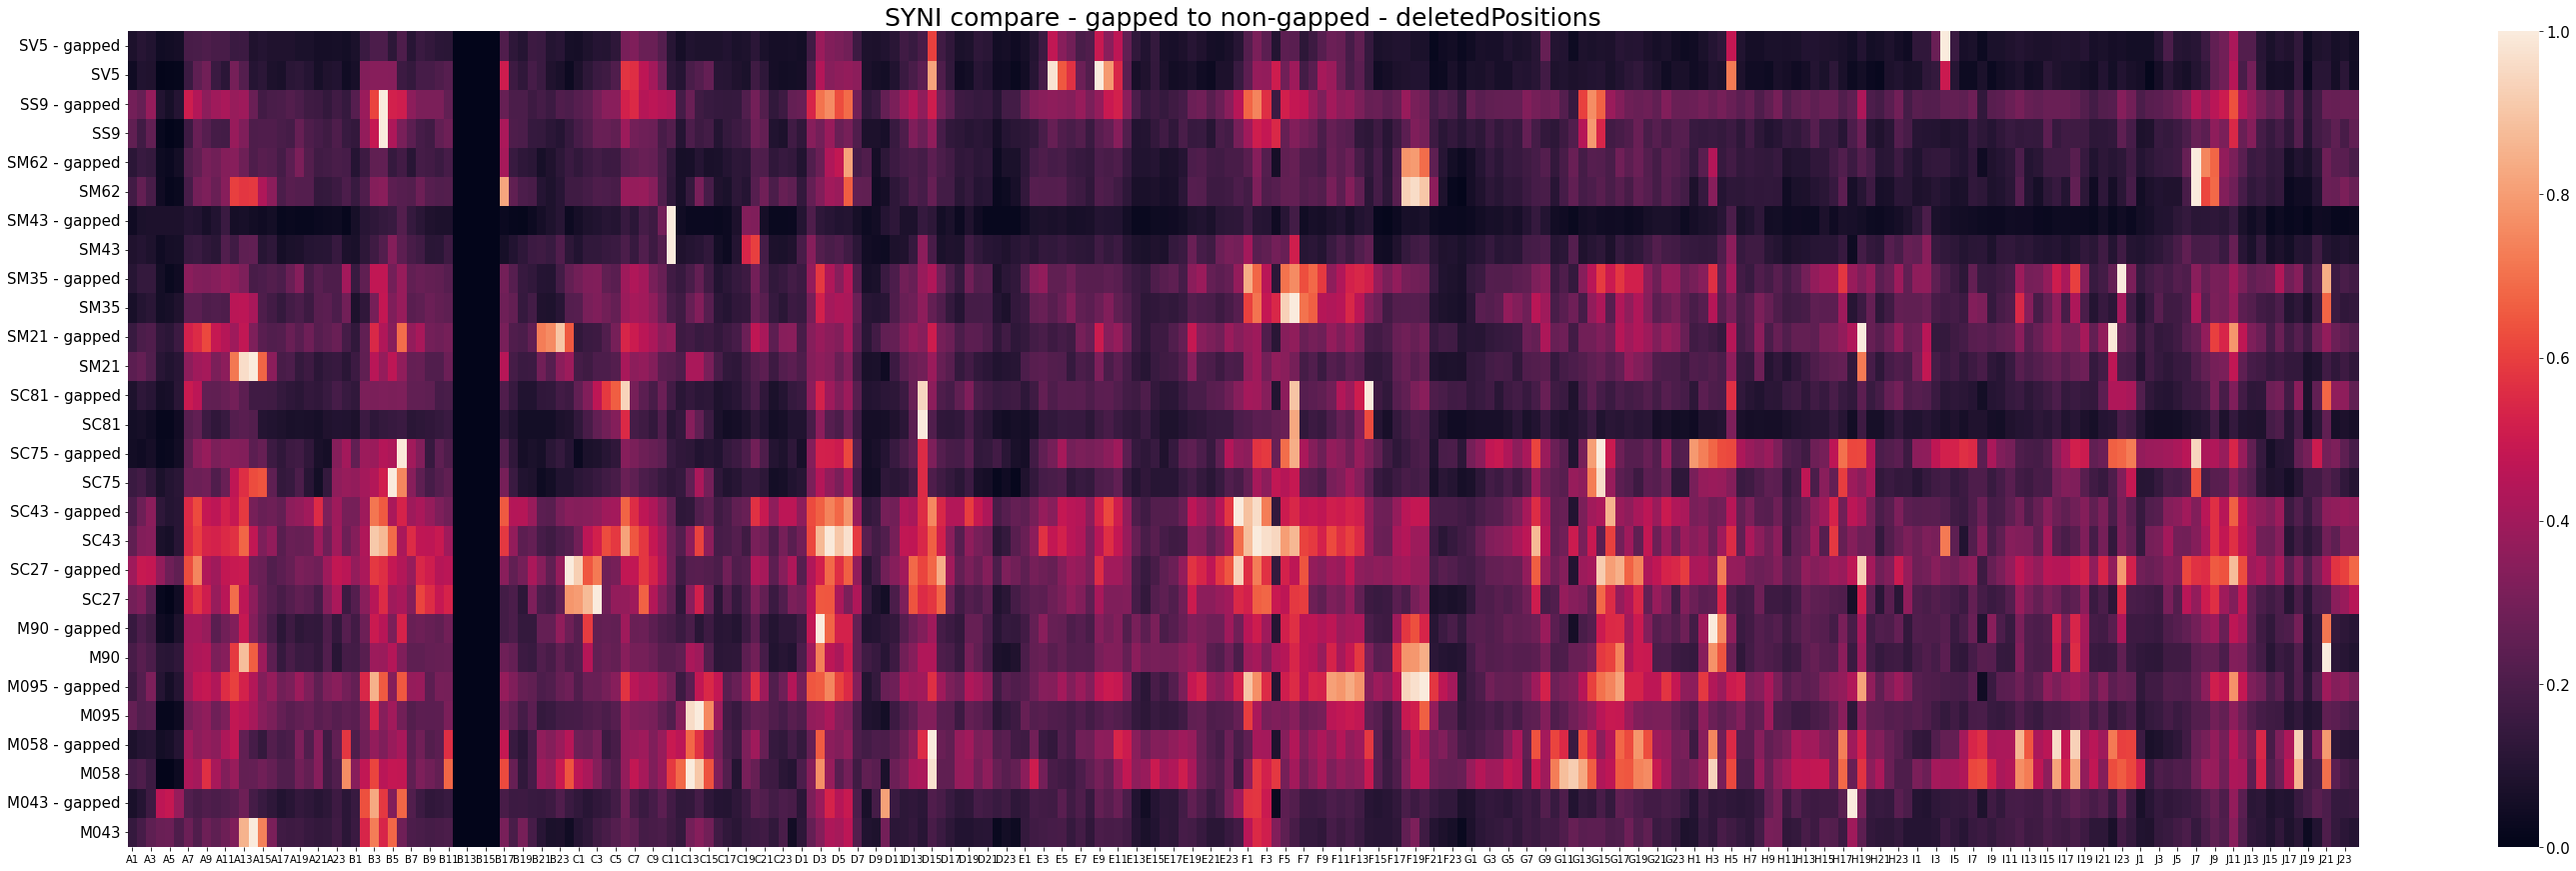

In [221]:
dPath = "C:/Users/KaiKr/Desktop/plots/SYNI- 102 - gapped.json"
with open(dPath) as file:
    data = json.load(file)

dPath = "C:/Users/KaiKr/Desktop/plots/SYNI.json"
with open(dPath) as file:
    dataA = json.load(file)
    
dPath = "C:/Users/KaiKr/Desktop/plots/SYNI- 102 - gapped.json"
with open(dPath) as file:
    dataB = json.load(file)
    
#scanFile(data)
scanFiles(dataA, dataB)
#scanFpFile()